# Task 1 - Req 3: Min-Conflicts và heuristic chọn biến
So sánh 3 cách chọn biến: `standard` (ngẫu nhiên trong các quân xung đột), `max_tabu` (nhiều xung đột nhất + tabu list) và `roulette` (ngẫu nhiên theo trọng số số xung đột). Số liệu thật nằm trong `data/measured/`, tạo bởi `python -m task1_nqueens.mc_experiment`.

In [1]:
from pathlib import Path
import sys
# Tìm thư mục chứa package task1_nqueens, chạy được từ bất kỳ thư mục con nào.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "task1_nqueens" / "data" / "measured").exists())
sys.path.insert(0, str(ROOT))
MEASURED = ROOT / "task1_nqueens" / "data" / "measured"
print("Root:", ROOT.name)

Root: build


## 1. Ví dụ nhỏ: N = 8
Mỗi nghiệm được kiểm tra độc lập bằng `Board.is_valid()` (biểu diễn `columns[row] = col`) và `slow_conflicts`.

In [2]:
from task1_nqueens.min_conflicts import MinConflictsSolver, slow_conflicts
from task1_nqueens.board import Board
for mode in ("standard", "max_tabu", "roulette"):
    res = MinConflictsSolver(8, max_steps=20000, mode=mode, tabu_size=2, restart_after=50).solve(seed=1)
    state = res["solution"]                       # state[col] = row
    board = Board(state)                          # đối xứng nên hợp lệ với biểu diễn còn lại
    assert res["success"] and slow_conflicts(state) == 0 and board.is_valid()
    print(mode, "steps =", res["steps"], "restarts =", res["restarts"], "solution =", state)
print(board)

standard steps = 60 restarts = 0 solution = [6, 1, 5, 2, 0, 3, 7, 4]
max_tabu steps = 64 restarts = 1 solution = [3, 1, 6, 2, 5, 7, 4, 0]
roulette steps = 78 restarts = 1 solution = [6, 4, 2, 0, 5, 7, 1, 3]
. . . . . . Q .
. . . . Q . . .
. . Q . . . . .
Q . . . . . . .
. . . . . Q . .
. . . . . . . Q
. Q . . . . . .
. . . Q . . . .


## 2. Bảng kết quả đo (30 seed, N = 8..200)
Số bước và thời gian tính trên mọi lần chạy, kể cả lần hết ngân sách (20000 bước). Với các dòng có thất bại, **mean bị kéo lên rất cao nên hãy đọc median và tỉ lệ thành công**.

In [3]:
import csv
from task1_nqueens.mc_experiment import summarize, print_summary, print_tabu_summary
def load(name):
    with (MEASURED / name).open() as f:
        return list(csv.DictReader(f))
no_restart, restart, tabu = load("minconf.csv"), load("minconf_restart.csv"), load("minconf_tabu.csv")
print("Số dòng:", len(no_restart), len(restart), len(tabu))
print("== KHÔNG restart =="); print_summary(summarize(no_restart))
print("== CÓ restart =="); print_summary(summarize(restart))

Số dòng: 540 540 900
== KHÔNG restart ==
Số bước và thời gian tính trên mọi lần chạy, gồm cả lần hết ngân sách.
   N variant    succ(%)   med_st  mean_st   std_st    ms/run  fail
   8 standard     100.0     41.5     43.6     29.4      0.20     0
   8 max_tabu      86.7     14.5   2680.7   6793.2     11.15     4
   8 roulette      93.3     43.0   1389.0   4974.3      6.87     2
  16 standard      93.3     73.5   1428.3   4964.6     10.19     2
  16 max_tabu     100.0     29.0     41.7     35.7      0.37     0
  16 roulette     100.0     62.5     86.7     82.1      0.78     0
  32 standard     100.0     79.5     84.0     34.6      1.04     0
  32 max_tabu     100.0     46.0     49.9     21.9      0.73     0
  32 roulette     100.0     84.0     87.0     50.5      1.27     0
  64 standard     100.0    111.0    116.2     35.5      3.10     0
  64 max_tabu     100.0     69.5     72.1     19.1      2.27     0
  64 roulette     100.0     97.5    107.6     40.2      3.18     0
 100 standard    

In [4]:
# Restart có thực sự được kích hoạt không? (đếm số lần chạy có restarts > 0)
from collections import Counter
c = Counter((int(r["N"]), r["variant"]) for r in restart if int(r["restarts"]) > 0)
for key in sorted(c): print(key, c[key], "/ 30 lần chạy dùng restart")

(8, 'max_tabu') 5 / 30 lần chạy dùng restart
(8, 'roulette') 11 / 30 lần chạy dùng restart
(8, 'standard') 8 / 30 lần chạy dùng restart
(16, 'max_tabu') 6 / 30 lần chạy dùng restart
(16, 'roulette') 11 / 30 lần chạy dùng restart
(16, 'standard') 11 / 30 lần chạy dùng restart
(32, 'max_tabu') 1 / 30 lần chạy dùng restart
(32, 'roulette') 6 / 30 lần chạy dùng restart
(32, 'standard') 6 / 30 lần chạy dùng restart
(64, 'max_tabu') 1 / 30 lần chạy dùng restart
(64, 'roulette') 5 / 30 lần chạy dùng restart
(64, 'standard') 4 / 30 lần chạy dùng restart
(100, 'roulette') 4 / 30 lần chạy dùng restart
(100, 'standard') 1 / 30 lần chạy dùng restart


## 3. Biểu đồ

minconf_steps_restart.png


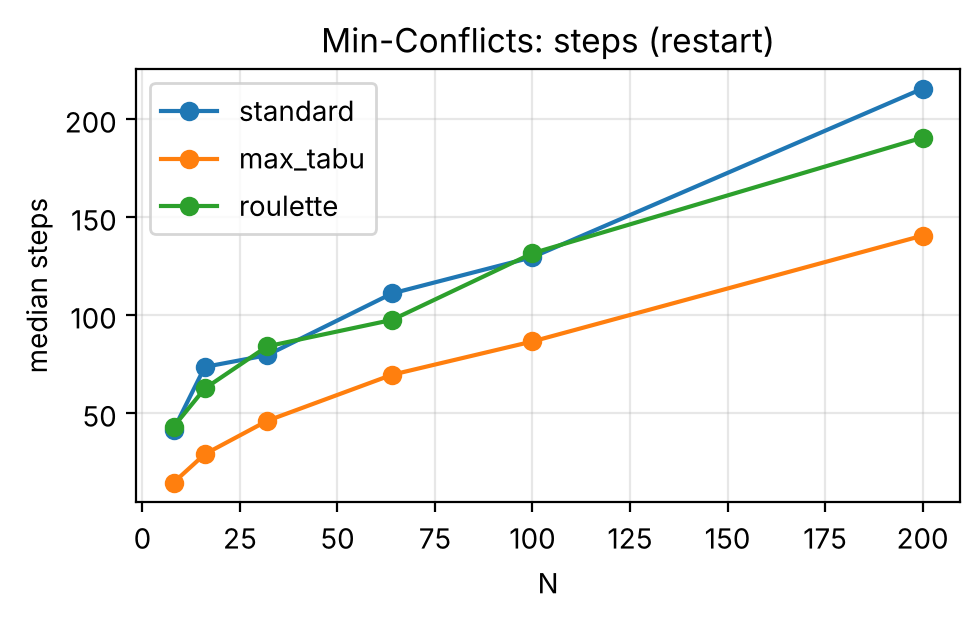

minconf_time_restart.png


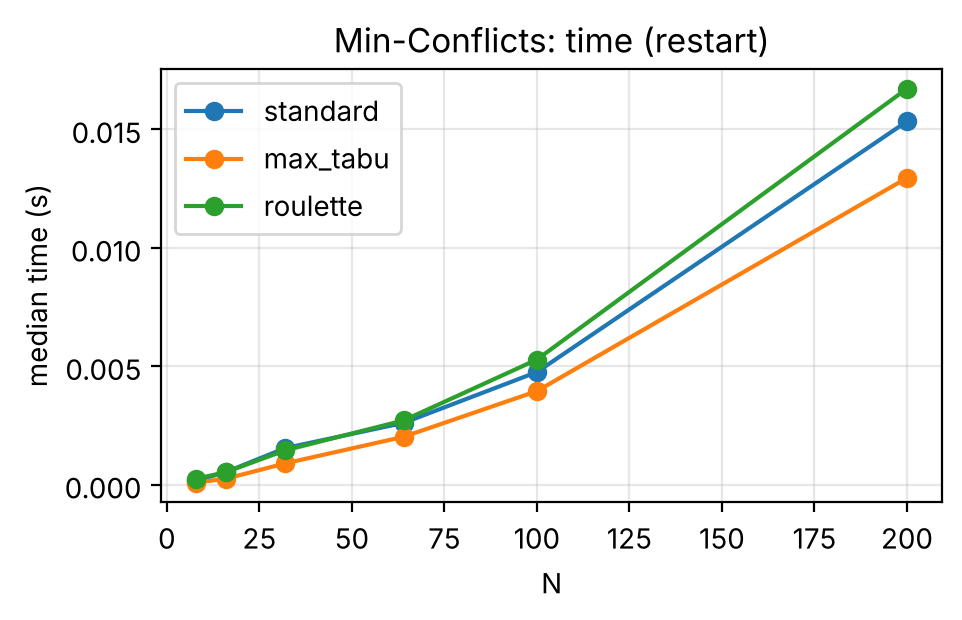

minconf_success.png


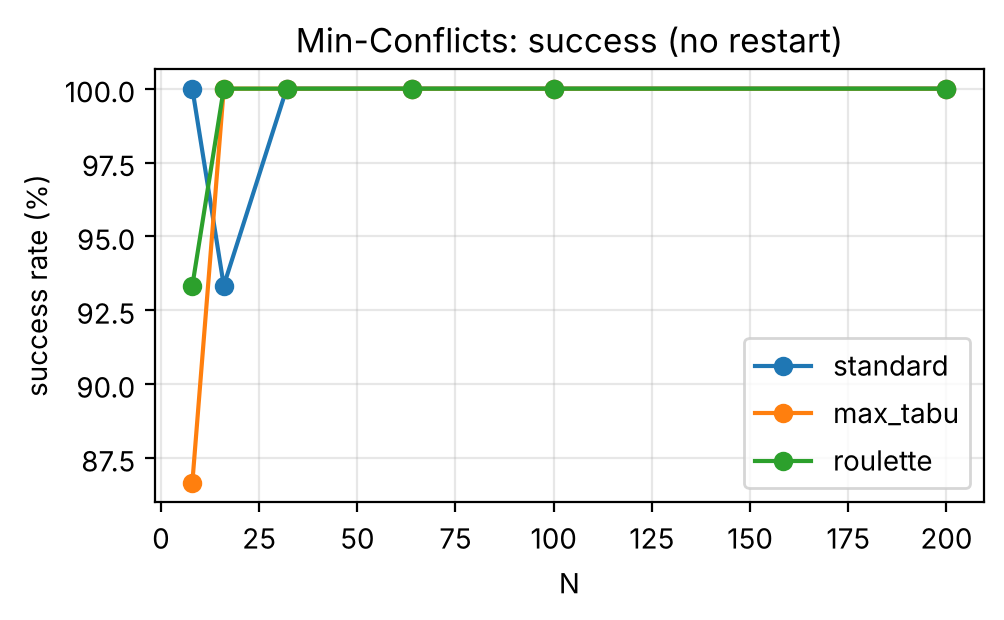

minconf_success_restart.png


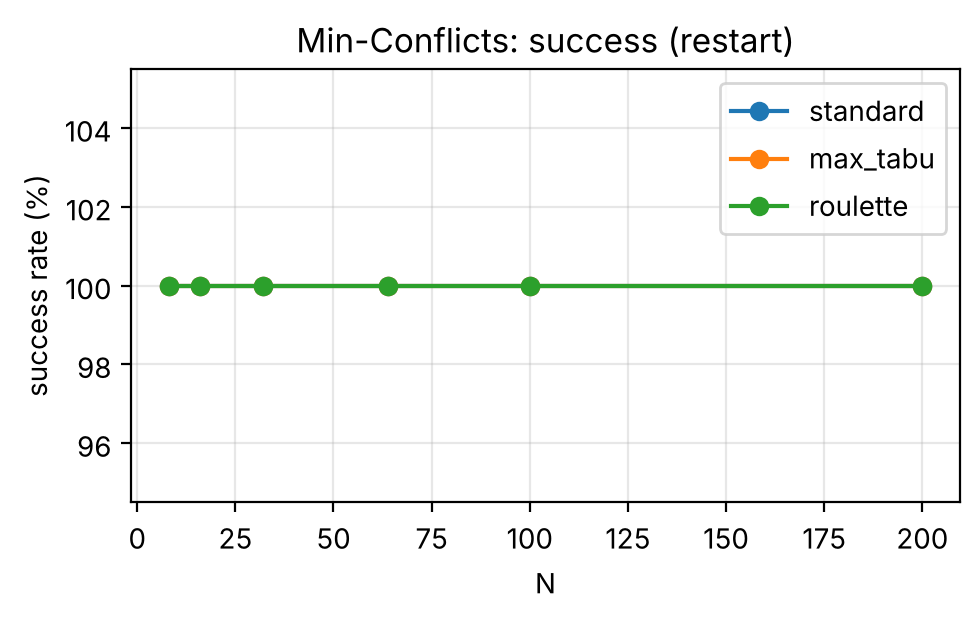

In [5]:
from task1_nqueens.analysis import plot_minconf, plot_tabu
from IPython.display import Image, display
fig = MEASURED / "figures"
plot_minconf(str(MEASURED / "minconf.csv"), str(fig))
plot_minconf(str(MEASURED / "minconf_restart.csv"), str(fig), suffix="_restart")
for name in ("minconf_steps_restart.png", "minconf_time_restart.png", "minconf_success.png", "minconf_success_restart.png"):
    print(name); display(Image(filename=str(fig / name), width=480))

## 4. Ảnh hưởng của `tabu_size` (max_tabu, có restart)
Giá trị mặc định trong thực nghiệm: `max(2, min(10, N // 5))`. `tabu_size = 0` nghĩa là chọn tham lam thuần túy, không tabu.

Thí nghiệm tabu_size của max_tabu (có restart): median số bước / tỉ lệ thành công
   N         tabu=0         tabu=2         tabu=5        tabu=10        tabu=20
   8    21.0 / 100%    14.5 / 100%    19.0 / 100%    16.0 / 100%    18.0 / 100%
  16    63.5 / 100%    34.0 / 100%    30.0 / 100%    34.5 / 100%    36.5 / 100%
  32    78.5 / 100%    47.5 / 100%    48.5 / 100%    60.0 / 100%    51.0 / 100%
  64    91.5 / 100%    74.5 / 100%    70.5 / 100%    69.5 / 100%    67.5 / 100%
 100   124.0 / 100%    83.5 / 100%    86.0 / 100%    86.5 / 100%    86.0 / 100%
 200   167.0 / 100%   139.5 / 100%   142.0 / 100%   140.5 / 100%   139.0 / 100%


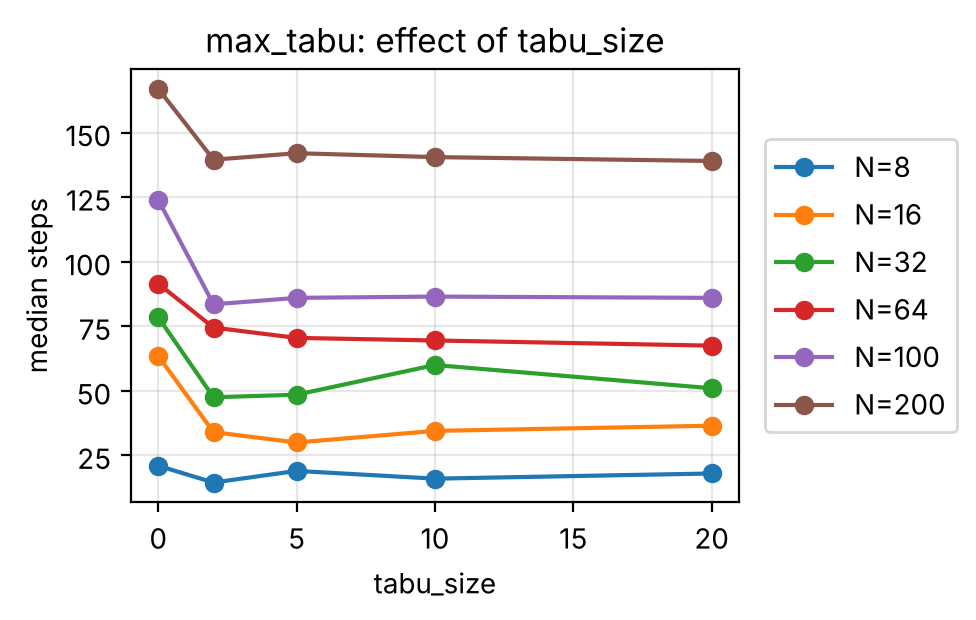

In [6]:
print_tabu_summary(tabu)
plot_tabu(str(MEASURED / "minconf_tabu.csv"), str(fig))
display(Image(filename=str(fig / "minconf_tabu.png"), width=520))

## 5. Chạy lại nhanh (live) để kiểm chứng
Chạy 5 seed ở N = 8, 16, 32, kết quả ghi ra thư mục tạm, không đè số liệu đo.

In [7]:
import tempfile
from task1_nqueens.mc_experiment import run_all
quick = run_all(n_values=[8, 16, 32], seeds=list(range(1, 6)), restart=True)
assert all(int(r["success"]) == 1 for r in quick)
print_summary(summarize(quick))

Số bước và thời gian tính trên mọi lần chạy, gồm cả lần hết ngân sách.
   N variant    succ(%)   med_st  mean_st   std_st    ms/run  fail
   8 standard     100.0     46.0     65.8     32.8      0.31     0
   8 max_tabu     100.0     10.0     23.8     25.1      0.21     0
   8 roulette     100.0     70.0     84.2     30.6      0.54     0
  16 standard     100.0     74.0    120.4    113.8      1.48     0
  16 max_tabu     100.0     15.0     27.8     28.0      0.40     0
  16 roulette     100.0     60.0     78.8     50.7      1.13     0
  32 standard     100.0    105.0    119.6     69.8      1.92     0
  32 max_tabu     100.0     35.0     33.6      9.7      0.76     0
  32 roulette     100.0     58.0     69.2     35.2      1.51     0


## 6. Nhận xét
- Min-Conflicts thuần (không restart) có thể bị kẹt cực trị cục bộ, kể cả `standard` (N=16: 2/30 lần thất bại). Có restart thì mọi cấu hình đạt 100%.
- `max_tabu` giảm khoảng 34-57% số bước so với `standard` ở mọi N và ổn định hơn (độ lệch chuẩn nhỏ hơn); thời gian giảm khoảng 15-45% (phụ thuộc máy chạy).
- `roulette` gần như ngang `standard`.
- Không restart, `max_tabu` có xu hướng kẹt nhiều hơn ở N nhỏ (4/30 ở N=8) vì chọn tham lam. Số lần thất bại ít nên chưa đủ để khẳng định chắc chắn.
- `tabu_size = 0` kém rõ rệt so với mọi giá trị >= 2; từ 2 đến 20 gần như không khác nhau, nên tabu nhỏ là đủ.